# Readaptation against a supervised reference

**Question.** A tag is placed in a room it has never seen. After how many queries does the adaptive loop answer about as well as a code fitted with every true label in that room, and at what uplink cost? This is the few-shot claim: zero-shot for the task (a pretrained teacher on the server), few-shot for the scene.

**Reference: the supervised code** (`experiments/supervised_ceiling.py`). For each room, a 96-region code is fitted with true labels on the room's own frames and scored on held-out contiguous time blocks (5 blocks, 10-frame gaps). It uses the same candidate table as the learner it is compared with: single pixels for the `*_pixels*` learners, cells for the others. It is a *reference*, not an upper bound. A fixed code can't follow a room that changes during a recording, and the loop can.

**Comparison.** The switch stream (`experiments/tiered_checks.py`) moves the tag through room A → Mall tile → room A rearranged, in one pass, so every frame is seen for the first time. For each room, queries are grouped by how long after the move they come. For each group, on exactly the same frames, the table gives:
* the share of the loop's answers that are correct, and the share of the supervised code's;
* the loop's uplink bytes per query and how often it fetched a full frame.

Plain accuracy (not balanced) is used here because a group can hold only one class; both are measured on the same frames, so the class mix is the same.

**Why not a single readaptation time.** "Queries until the code is redeployed" depends on when the server notices the move, and that depends on the teacher (`tiered_checks.ipynb` section 5). "Queries until accuracy is within ε" is met at once, because the loop answers from full frames while it bootstraps. A recovery time needs both accuracy and a byte budget, and over one pass the loop does not settle into one state (section 5), so the grouped table is the summary.

## 1. Load replays and the supervised codes

In [10]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path('..').resolve()))
from semwisp import piropo

RES = piropo.REPO / 'results'
ROOM = {'room A (training)': 'A', 'room B (mall tile)': 'mall', 'room A, rearranged': 'A2', 'room A, rearranged (test2)': 'A2'}
ROOMS = ['A', 'mall', 'A2']
ROOM_NAME = {'A': 'room A (first room)', 'mall': 'Mall tile (after the 1st move)', 'A2': 'room A rearranged (after the 2nd move)'}
BINS = [0, 100, 300, 1000, 10 ** 6]
BIN_NAMES = ['0-99', '100-299', '300-999', '1000+']
TEACHERS = ['detector', 'fcos', 'oracle']
BLUE, ORANGE, AQUA, GRAY, MAGENTA = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984', '#e87ba4'
TCOLOR = dict(detector=ORANGE, fcos=BLUE, oracle=GRAY)

ceiling = {}
rows = []
for f in sorted((RES / 'supervised_ceiling').glob('*.npz')):
    z = np.load(f)
    room, fitter, table = f.stem.split('_')
    ok = ~np.isnan(z['logit']) & (z['label'] >= 0)
    ans, y = (z['logit'][ok] > 0).astype(int), z['label'][ok]
    rows.append(dict(room=room, fitter=fitter, table=table, balanced_acc=((ans[y == 1]).mean() + (1 - ans[y == 0]).mean()) / 2,
                     auc=piropo.auc(z['logit'][ok], y)))
    if fitter == 'batch':
        ceiling[room, table] = dict(zip(z['t'].tolist(), (z['logit'] > 0).astype(int)))
ceil_tab = pd.DataFrame(rows).pivot_table(index=['fitter', 'table'], columns='room', values=['balanced_acc', 'auc'])[['balanced_acc', 'auc']]
print('Supervised codes on held-out time blocks (fitter batch = the reference used below)')
ceil_tab.round(3)

Supervised codes on held-out time blocks (fitter batch = the reference used below)


balanced_acc                  auc              
room                     A     A2   mall      A     A2   mall
fitter table                                                 
batch  cells         0.818  0.834  0.956  0.926  0.820  0.975
       pixels        0.767  0.788  0.956  0.832  0.869  0.977
online cells         0.904  0.735  0.885  0.931  0.911  0.966
       pixels        0.798  0.650  0.847  0.867  0.621  0.932

In [11]:
runs = {}
for f in sorted((RES / 'tiered_checks').glob('switch_*_b200.npz')):
    z = np.load(f)
    m = json.loads(str(z['meta']))
    n = len(z['label'])
    df = pd.DataFrame({k: z[k] for k in z.files if k != 'meta' and z[k].shape == (n,)})
    df['room'] = df.seq.map(ROOM)
    df['q'] = df.groupby('room', sort=False).cumcount()        # queries since the tag arrived in this room
    table = 'pixels' if 'pixels' in m['learner'] else 'cells'
    df['ref'] = [ceiling[r, table].get(t, -1) for r, t in zip(df.room, df.t.tolist())]
    runs[m['teacher'], m['learner'], m['check']] = df
print(len(runs), 'switch-stream runs; learners:', sorted({k[1] for k in runs}))

30 switch-stream runs; learners: ['batch_cells', 'online_cells', 'online_cells_cal', 'online_pixels', 'online_pixels_cal']


## 2. The runs at a glance

**What is varied.** A run combines one teacher, one learner and one kind of check, and is replayed on the switch stream. The supervised code is the reference every run is compared with; it never runs in the loop.

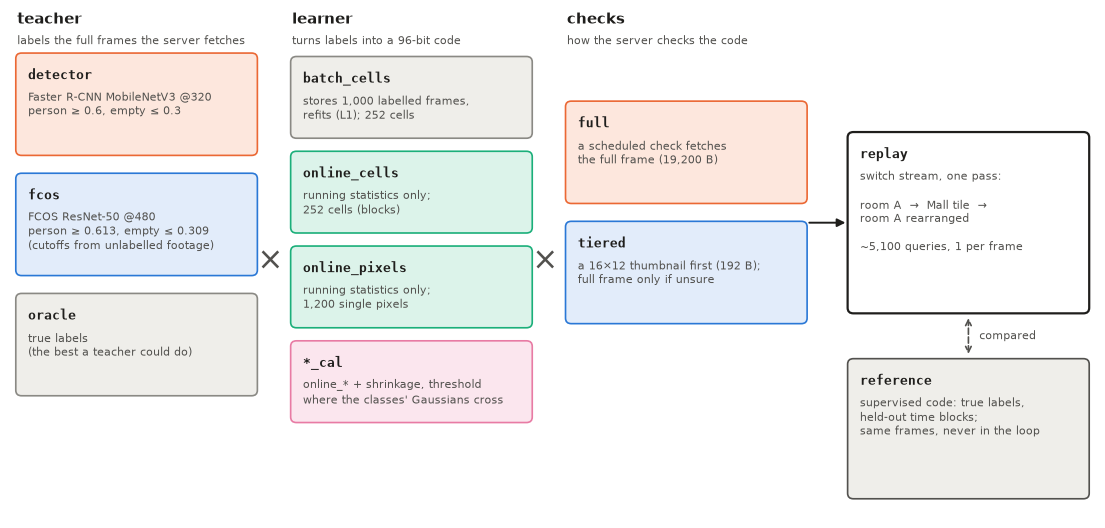

In [12]:
from matplotlib.patches import FancyBboxPatch
INK, MUTED, LINE = '#1f1e1c', '#52514e', '#d6d5d0'
TINT = dict(orange='#fde7dd', blue='#e2ecfa', gray='#efeeea', aqua='#dcf3ea', magenta='#fbe6ee')

def box(ax, x, y, w, h, title, sub='', fc='white', ec=MUTED, lw=1.2, fs=9):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02,rounding_size=0.08', fc=fc, ec=ec, lw=lw))
    ax.text(x + 0.15, y + h - 0.2, title, fontsize=fs, fontweight='bold', color=INK, va='top', family='monospace')
    if sub:
        ax.text(x + 0.15, y + h - 0.52, sub, fontsize=7.8, color=MUTED, va='top', linespacing=1.3)

def arrow(ax, x0, y0, x1, y1, color=MUTED, lw=1.4):
    ax.annotate('', (x1, y1), (x0, y0), arrowprops=dict(arrowstyle='-|>', color=color, lw=lw, shrinkA=0, shrinkB=0,
                                                        mutation_scale=12))

fig, ax = plt.subplots(figsize=(14, 6.6))
ax.set_xlim(0, 15); ax.set_ylim(0, 7.4); ax.axis('off')
cols = [(0.1, 'teacher', 'labels the full frames the server fetches'),
        (3.9, 'learner', 'turns labels into a 96-bit code'),
        (7.7, 'checks', 'how the server checks the code')]
for x, t, s in cols:
    ax.text(x, 7.2, t, fontsize=11, fontweight='bold', color=INK)
    ax.text(x, 6.9, s, fontsize=8, color=MUTED)
teach = [('detector', 'Faster R-CNN MobileNetV3 @320\nperson ≥ 0.6, empty ≤ 0.3', TINT['orange'], ORANGE),
         ('fcos', 'FCOS ResNet-50 @480\nperson ≥ 0.613, empty ≤ 0.309\n(cutoffs from unlabelled footage)', TINT['blue'], BLUE),
         ('oracle', 'true labels\n(the best a teacher could do)', TINT['gray'], GRAY)]
for k, (t, s, fc, ec) in enumerate(teach):
    box(ax, 0.1, 5.3 - k * 1.75, 3.3, 1.45, t, s, fc, ec)
learn = [('batch_cells', 'stores 1,000 labelled frames,\nrefits (L1); 252 cells', TINT['gray'], GRAY),
         ('online_cells', 'running statistics only;\n252 cells (blocks)', TINT['aqua'], AQUA),
         ('online_pixels', 'running statistics only;\n1,200 single pixels', TINT['aqua'], AQUA),
         ('*_cal', 'online_* + shrinkage, threshold\nwhere the classes\' Gaussians cross', TINT['magenta'], MAGENTA)]
for k, (t, s, fc, ec) in enumerate(learn):
    box(ax, 3.9, 5.55 - k * 1.38, 3.3, 1.15, t, s, fc, ec)
checks = [('full', 'a scheduled check fetches\nthe full frame (19,200 B)', TINT['orange'], ORANGE),
          ('tiered', 'a 16×12 thumbnail first (192 B);\nfull frame only if unsure', TINT['blue'], BLUE)]
for k, (t, s, fc, ec) in enumerate(checks):
    box(ax, 7.7, 4.6 - k * 1.75, 3.3, 1.45, t, s, fc, ec)
for x in (3.5, 7.3):
    ax.text(x + 0.1, 3.75, '×', fontsize=22, color=MUTED, ha='center', va='center')
# the run and the stream
box(ax, 11.6, 3.0, 3.3, 2.6, 'replay', 'switch stream, one pass:\n\nroom A  →  Mall tile  →\nroom A rearranged\n\n~5,100 queries, 1 per frame', 'white', INK, lw=1.6)
arrow(ax, 11.05, 4.3, 11.55, 4.3, INK)
# the reference
box(ax, 11.6, 0.3, 3.3, 2.0, 'reference', 'supervised code: true labels,\nheld-out time blocks;\nsame frames, never in the loop', TINT['gray'], MUTED)
ax.annotate('', (13.25, 2.95), (13.25, 2.35), arrowprops=dict(arrowstyle='<->', color=MUTED, lw=1.2, ls='--'))
ax.text(13.4, 2.65, 'compared', fontsize=8, color=MUTED, va='center')
plt.show()

**Example frames, and what the tag reads.** One empty and one person frame per room, late in each room's stretch. The 96 dots are the pixels of the code the server had deployed at that moment (`switch_fcos_online_pixels_cal_tiered_b200`, recorded by `experiments/code_snapshots.py`). A filled orange dot is a set bit: that pixel's gray level is outside its usual range. The tag sends only those 96 bits (12 bytes); the server's decoder turns them into the answer.

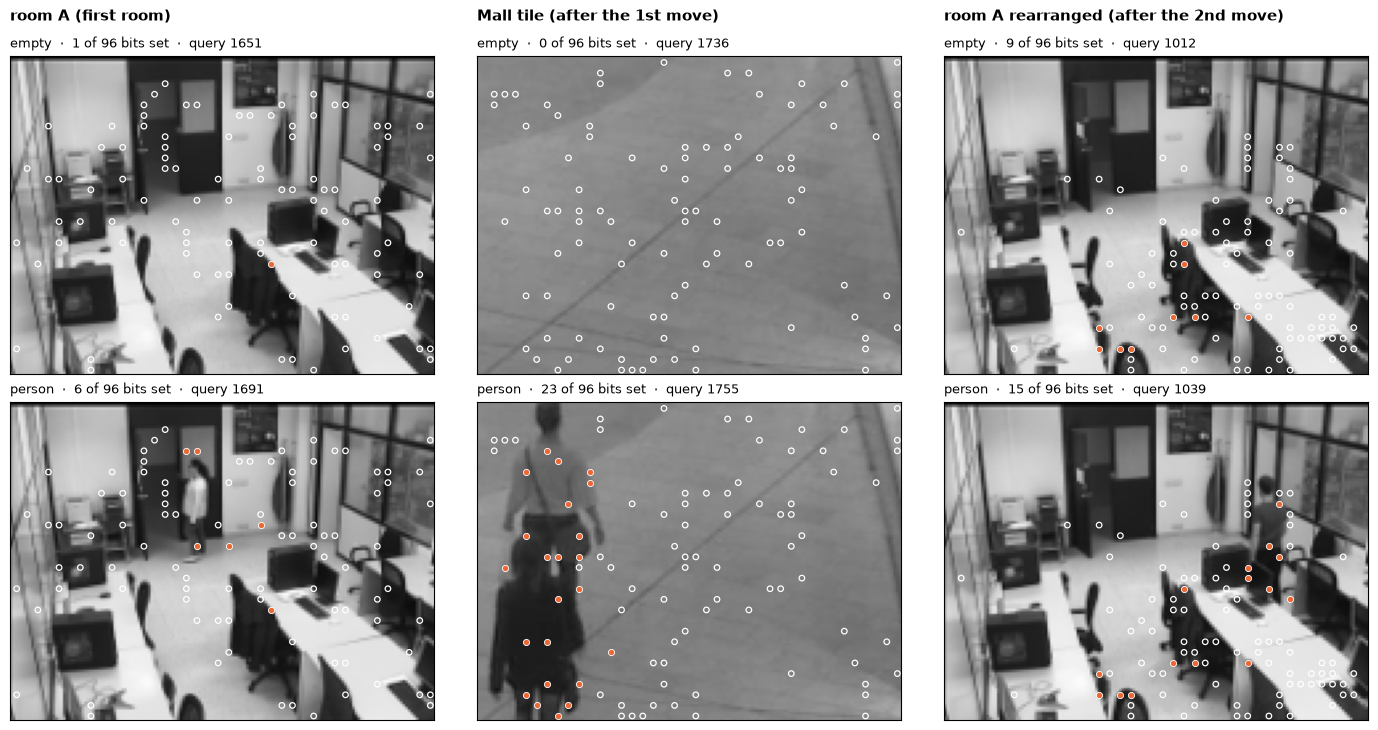

In [13]:
from semwisp.frames import load_frames, load_mall_tile
from semwisp.tag.interval import IntervalCode, cell_sums, code_bits

RUN = ('fcos', 'online_pixels_cal', 'tiered')
snap = np.load(RES / 'tiered_checks' / 'snapshots' / 'switch_fcos_online_pixels_cal_tiered_b200.npz')
P = {n: s for n, s in load_frames(['training', 'training_seats', 'test2']).items()}
SRC = {'room A (training)': P['training'], 'room A, rearranged': P['training_seats'],
       'room A, rearranged (test2)': P['test2'], 'room B (mall tile)': load_mall_tile()}
STRIDE = {'room B (mall tile)': 1}

df = runs[RUN].reset_index(drop=True)
def frame_of(row):
    return SRC[row.seq]['X'][int(row.idx) * STRIDE.get(row.seq, 2)]
assert all((SRC[s]['t'][df.idx[df.seq == s].values * STRIDE.get(s, 2)] == df.t[df.seq == s].values).all() for s in SRC)

def pick(room, label):
    # a late query in the room, answered by the code alone, answered correctly, with that label
    g = df[(df.room == room) & (df.label == label) & df.used_code.astype(bool) & ~df.explored.astype(bool)
           & (df.answer == df.label)]
    return g.iloc[int(len(g) * 0.85)]

fig, axs = plt.subplots(2, 3, figsize=(14, 7.2), constrained_layout=True)
for j, room in enumerate(ROOMS):
    for i, label in enumerate((0, 1)):
        row = pick(room, label)
        k = np.searchsorted(snap['query'], row.name, side='right') - 1          # the code active at that query
        rects = snap['rects'][k]
        code = IntervalCode(np.arange(len(rects)), snap['lo'][k], snap['hi'][k], rects)
        f = frame_of(row)
        bits = code_bits(cell_sums(f, rects), code)
        ax = axs[i, j]
        ax.imshow(f, cmap='gray', vmin=0, vmax=255)
        cx, cy = rects[:, 0] + rects[:, 4] // 2, rects[:, 1] + rects[:, 4] // 2
        ax.scatter(cx[bits == 0], cy[bits == 0], s=16, facecolor='none', edgecolor='white', lw=0.9)
        ax.scatter(cx[bits == 1], cy[bits == 1], s=20, color=ORANGE, edgecolor='white', lw=0.6)
        ax.set_xticks([]); ax.set_yticks([])
        teacher = runs[RUN].score.iloc[row.name]
        ax.set_title(f"{'person' if label else 'empty'}  ·  {int(bits.sum())} of 96 bits set  ·  query {row.q}",
                     fontsize=9, loc='left')
        if i == 0:
            ax.text(0, 1.1, ROOM_NAME[room], transform=ax.transAxes, fontsize=10.5, fontweight='bold', va='bottom')
plt.show()

**Accuracy over time, all methods.** The whole switch stream, left to right, in 100-query windows (no window spans a move). Each row is one method, colored by the share of correct answers in the window; the reference rows show the supervised codes on the same frames. Top: every learner with the FCOS teacher; middle: the calibrated 96-pixel learner with each teacher; bottom: uplink bytes per query (log color) for the same rows as the middle. All rows use tiered checks.

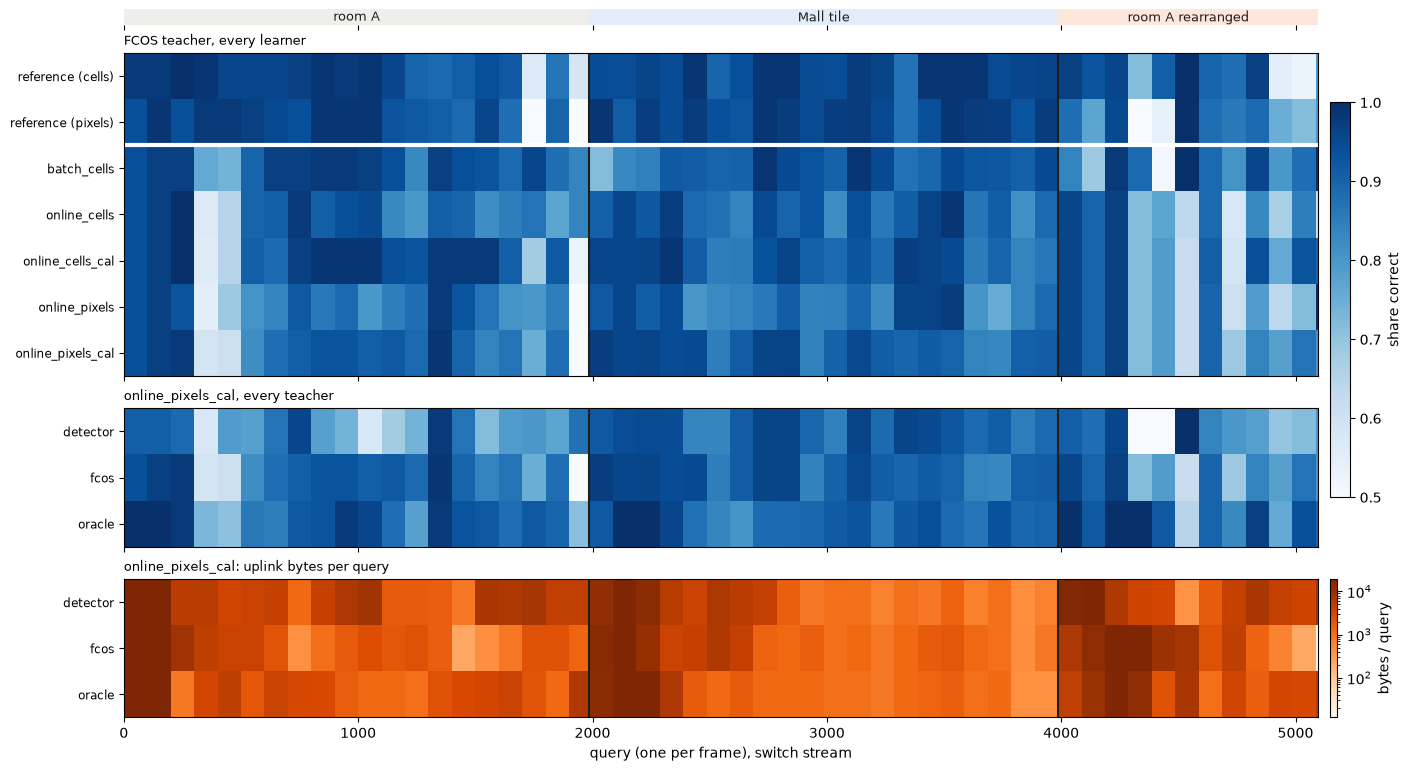

In [14]:
WIN = 100
starts = {}
q0 = 0
for room in ROOMS:                                          # stream order: A, Mall tile, A2
    n = (runs[RUN].room == room).sum()
    starts[room] = (q0, n); q0 += n
edges = np.concatenate([[starts[r][0] + e for e in list(range(0, starts[r][1], WIN))] for r in ROOMS] + [[q0]])

def windows(df, value):
    out = []
    for room in ROOMS:
        g = df[df.room == room].reset_index(drop=True)
        for a in range(0, len(g), WIN):
            out.append(value(g.iloc[a:a + WIN]))
    return np.array(out, float)

acc = lambda h: (h.answer == h.label)[h.label >= 0].mean()
ref = lambda h: (h.ref == h.label)[h.label >= 0].mean()
byt = lambda h: h.up_bytes.mean()

top = [('reference (cells)', 'fcos', 'online_cells', ref), ('reference (pixels)', 'fcos', 'online_pixels', ref)] + \
      [(l, 'fcos', l, acc) for l in ['batch_cells', 'online_cells', 'online_cells_cal', 'online_pixels', 'online_pixels_cal']]
mid = [(f'{t}', t, 'online_pixels_cal', acc) for t in TEACHERS]
A_top = np.array([windows(runs[t, l, 'tiered'], f) for _, t, l, f in top])
A_mid = np.array([windows(runs[t, l, 'tiered'], f) for _, t, l, f in mid])
B_mid = np.array([windows(runs[t, l, 'tiered'], byt) for _, t, l, f in mid])

from matplotlib.colors import LogNorm
fig, axs = plt.subplots(4, 1, figsize=(14, 7.6), sharex=True, constrained_layout=True,
                        gridspec_kw=dict(height_ratios=[0.35, len(top), len(mid), len(mid)]))
band = axs[0]
for room, c in zip(ROOMS, (TINT['gray'], TINT['blue'], TINT['orange'])):
    a, n = starts[room]
    band.axvspan(a, a + n, color=c)
    band.text(a + n / 2, 0.5, {'A': 'room A', 'mall': 'Mall tile', 'A2': 'room A rearranged'}[room], ha='center', va='center', fontsize=9, color=INK)
band.set_yticks([]); band.set_ylim(0, 1)
for s in band.spines.values(): s.set_visible(False)
kw = dict(cmap='Blues', vmin=0.5, vmax=1.0)
m1 = axs[1].pcolormesh(edges, np.arange(len(top) + 1), A_top, **kw)
axs[2].pcolormesh(edges, np.arange(len(mid) + 1), A_mid, **kw)
m3 = axs[3].pcolormesh(edges, np.arange(len(mid) + 1), B_mid, cmap='Oranges', norm=LogNorm(12, 19200))
for ax, rows, title in [(axs[1], top, 'FCOS teacher, every learner'), (axs[2], mid, 'online_pixels_cal, every teacher'),
                        (axs[3], mid, 'online_pixels_cal: uplink bytes per query')]:
    ax.set_yticks(np.arange(len(rows)) + 0.5, [r[0] for r in rows], fontsize=8.5)
    ax.invert_yaxis()
    ax.set_title(title, loc='left', fontsize=9.5)
    for room in ROOMS[1:]:
        ax.axvline(starts[room][0], color=INK, lw=1.5)
axs[1].axhline(2, color='white', lw=3)                       # reference rows apart from the learners
axs[-1].set_xlabel('query (one per frame), switch stream')
fig.colorbar(m1, ax=axs[1:3], label='share correct', shrink=0.8, pad=0.01)
fig.colorbar(m3, ax=axs[3], label='bytes / query', pad=0.01)
plt.show()

## 3. Accuracy and cost by time since the move

In [15]:
rows = []
for (teacher, learner, check), df in runs.items():
    d = df[df.label >= 0].copy()
    d['bin'] = pd.cut(d.q, BINS, right=False, labels=BIN_NAMES)
    for (room, b), g in d.groupby(['room', 'bin'], observed=True):
        rows.append(dict(teacher=teacher, learner=learner, check=check, room=room, bin=b, queries=len(g),
                         loop=(g.answer == g.label).mean(), reference=(g.ref == g.label).mean(),
                         bytes_per_query=df.loc[g.index, 'up_bytes'].mean(), full_rate=g.explored.mean()))
H = pd.DataFrame(rows)
H['gap'] = H.loop - H.reference
H['room'] = pd.Categorical(H.room, ROOMS, ordered=True)

def show(learners, check, value, fmt):
    t = H[H.learner.isin(learners) & (H.check == check)].pivot_table(
        index=['room', 'learner'], columns=['bin', 'teacher'], values=value, observed=True)
    t = t.reindex(columns=pd.MultiIndex.from_product([BIN_NAMES, TEACHERS]))
    return t.style.format(fmt, na_rep='–')

MAIN = sorted(H.learner.unique(), key=lambda l: (l.replace('_cal', ''), l))
print('loop accuracy minus the supervised code\'s, same frames (tiered checks)')
show(MAIN, 'tiered', 'gap', '{:+.3f}').background_gradient(cmap='RdYlGn', vmin=-0.2, vmax=0.2)

loop accuracy minus the supervised code's, same frames (tiered checks)


In [16]:
print('uplink bytes per query (tiered checks)')
show(MAIN, 'tiered', 'bytes_per_query', '{:,.0f}')

uplink bytes per query (tiered checks)


In [8]:
print('loop accuracy minus the supervised code\'s (full-frame checks)')
show(MAIN, 'full', 'gap', '{:+.3f}').background_gradient(cmap='RdYlGn', vmin=-0.2, vmax=0.2)

loop accuracy minus the supervised code's (full-frame checks)


## 4. Curves after each move

Accuracy gap to the supervised code (top) and uplink bytes per query (bottom, log scale), in 100-query windows, for the 96-pixel online learner with tiered checks (the method). Dashed: the calibrated decoder (`*_cal`), where it has been run.

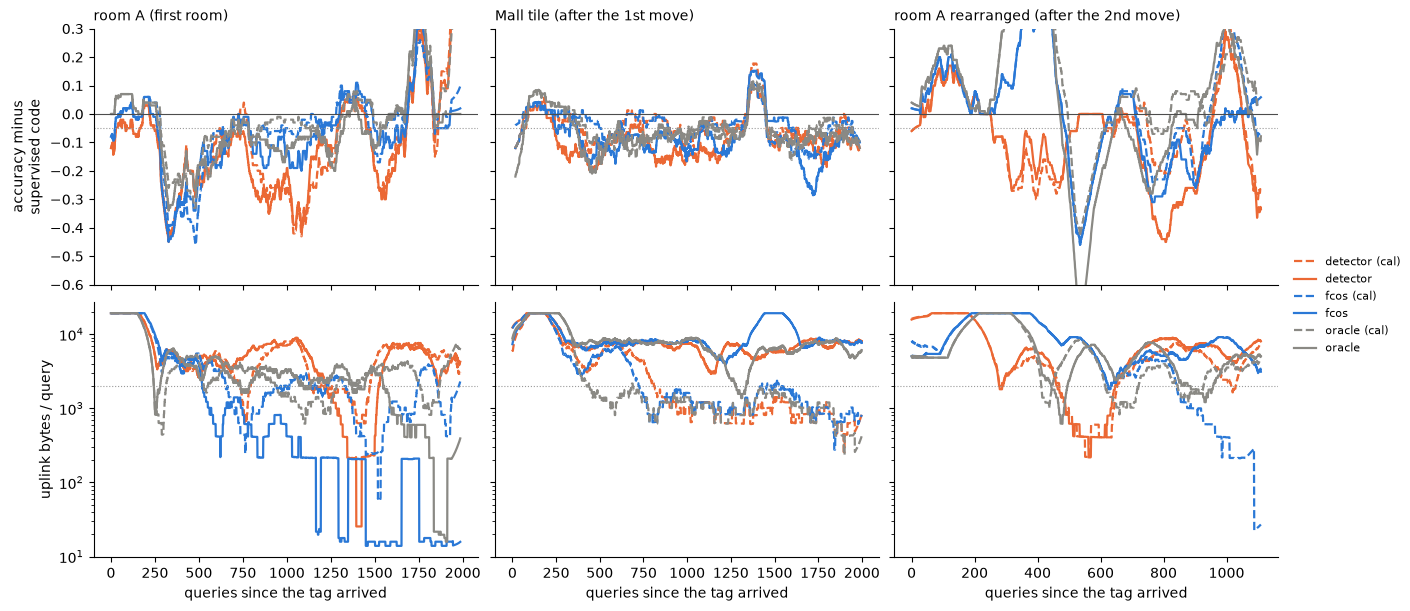

In [9]:
W = 100
def windowed(df, room):
    g = df[df.room == room].reset_index(drop=True)
    ok = g.label >= 0
    gap = ((g.answer == g.label).astype(float).where(ok) - (g.ref == g.label).astype(float).where(ok)).rolling(W, min_periods=W // 2, center=True).mean()
    return g.q, gap, g.up_bytes.rolling(W, min_periods=W // 2, center=True).mean()

fig, axs = plt.subplots(2, 3, figsize=(14, 6), sharex='col', sharey='row', constrained_layout=True)
for j, room in enumerate(ROOMS):
    for (teacher, learner, check), df in runs.items():
        if check != 'tiered' or learner not in ('online_pixels', 'online_pixels_cal'):
            continue
        q, gap, by = windowed(df, room)
        ls = '--' if learner.endswith('_cal') else '-'
        axs[0, j].plot(q, gap, color=TCOLOR[teacher], ls=ls, lw=1.6, label=f'{teacher}{" (cal)" if ls == "--" else ""}')
        axs[1, j].plot(q, by, color=TCOLOR[teacher], ls=ls, lw=1.6)
    axs[0, j].axhline(0, color='0.3', lw=0.8); axs[0, j].axhline(-0.05, color='0.6', lw=0.8, ls=':')
    axs[1, j].axhline(2000, color='0.6', lw=0.8, ls=':')
    axs[0, j].set_title(ROOM_NAME[room], loc='left', fontsize=10)
    axs[1, j].set_yscale('log'); axs[1, j].set_xlabel('queries since the tag arrived')
    for ax in axs[:, j]:
        for s in ('top', 'right'): ax.spines[s].set_visible(False)
axs[0, 0].set_ylabel('accuracy minus\nsupervised code'); axs[1, 0].set_ylabel('uplink bytes / query')
axs[0, 0].set_ylim(-0.6, 0.3)
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc='outside right center', frameon=False, fontsize=8)
plt.show()

## 5. A single recovery time is fragile

Recovered at query *q* if the 100-query window starting at *q* is within 0.05 of the supervised code *and* averages at most 2,000 uplink bytes per query (about 10% full frames). `held` is the share of later windows that also qualify.

In [10]:
rows = []
for (teacher, learner, check), df in runs.items():
    for room in ROOMS:
        g = df[df.room == room].reset_index(drop=True)
        ok = g.label >= 0
        fw = lambda s: s.rolling(W, min_periods=W // 2).mean().shift(-(W - 1))
        good = (fw((g.answer == g.label).astype(float).where(ok)) >= fw((g.ref == g.label).astype(float).where(ok)) - 0.05) & (fw(g.up_bytes) <= 2000)
        q = int(good.idxmax()) if good.any() else None
        rows.append(dict(teacher=teacher, learner=learner, check=check, room=room, recovered_at=q,
                         kB_until=None if q is None else g.up_bytes[:q].sum() / 1e3,
                         held=None if q is None else good[q:len(g) - W].mean()))
rec = pd.DataFrame(rows)
rec['room'] = pd.Categorical(rec.room, ROOMS, ordered=True)
(rec[rec.check == 'tiered'].pivot_table(index=['room', 'learner'], columns='teacher', values=['recovered_at', 'held'], observed=True)
    .style.format('{:.0f}', subset='recovered_at', na_rep='never').format('{:.2f}', subset='held', na_rep='–'))

## 6. Why the online learner lags: its decoder

`experiments/learner_ablation.py` swaps the online learner's three parts (interval rule, region selection, decoder) for the batch fit's, one at a time, with every true label of a room and the same held-out blocks. Balanced accuracy:

In [11]:
ab = pd.read_csv(RES / 'learner_ablation' / 'results.csv')
(ab.pivot_table(index=['intervals', 'selection', 'decoder'], columns=['room', 'table'], values=['balanced_accuracy', 'auc'])
   .style.format('{:.3f}').background_gradient(cmap='RdYlGn', vmin=0.65, vmax=1.0))

## Findings

* **The supervised code is a reference, not a ceiling, in PIROPO.** Fitted with every true label and scored on held-out time blocks, a fixed 96-region code reaches 0.77–0.82 balanced accuracy in room A and 0.79–0.83 in A2 (batch fit; section 1), against 0.96 on the stationary Mall tile. PIROPO's rooms change during a recording (staged scenarios, lighting), and a code fitted on other stretches transfers imperfectly. The clearest case is the end of room A2 (queries 1,000+): its last 40 queries before `test2` are 92% empty, and the fixed code calls half of them person (0.55 correct, against the loop's 0.93). That is why every learner there is 0.3–0.4 *above* the reference with cell codes.
* **The calibrated decoder (`*_cal`) makes the Mall tile cheap.** With the 96-pixel online learner and tiered checks, from query 1,000 on it sends 970–1,216 bytes per query instead of 5,575–9,801 (5–8× less) and moves closer to the reference (−0.05 / −0.06 / −0.05 against −0.09 / −0.08 / −0.06 for the old teacher / FCOS / true labels). Over queries 300–999 the gap halves (about −0.04 against −0.10 with FCOS) at half the bytes. Before calibration the code ranked Mall frames well but put its threshold in the wrong place, so checks kept disagreeing and full frames kept being fetched.
* **With FCOS and the calibrated 96-pixel learner (tiered checks), the method's profile** (gap to the reference, bytes per query) is:
  * room A, cold start: 0.00 at 19,200 B (queries 0–99, bootstrap); +0.01 at 14,000 B (100–299); −0.16 at 2,600 B (300–999); +0.01 at 1,600 B (1,000+);
  * Mall tile, after the first move: −0.01 at 15,900 B; +0.01 at 14,800 B; −0.04 at 3,500 B; −0.06 at 1,200 B;
  * room A rearranged, after the second move: +0.08 at 6,800 B; +0.08 at 16,300 B; 0.00 at 6,500 B; +0.14 at 200 B.
  So within 300–1,000 queries of a move the loop is within about 0.05 of a code fitted with every label, at 1–4 kB per query. Steady state is still 100× the 12-byte code, because checks (192-byte thumbnails, 19,200-byte full frames) dominate.
* **Room A's middle stretch (queries 300–999) is the weak spot for every learner and teacher** (−0.12 to −0.24, true labels included). The reference there is fitted partly on *later* frames of the recording, which the loop has not seen yet, so part of this gap is hindsight.
* **The calibrated decoder is not free in room A.** From query 1,000 on it is more accurate there (FCOS: +0.01 against −0.01; true labels: +0.06 against −0.01) but sends more bytes (1,600 against 115 with FCOS). It checks far more often: with FCOS, thumbnails on 31.8% of those queries instead of 3.1%, and full frames on 8.1% instead of 0.5% (mostly *unsure* and *disagree*). Why its answers trigger more checks there is not yet known.
* **A single recovery time is fragile** (section 5). With a 0.05 tolerance and a 2,000-byte budget, the first qualifying window comes after 50–1,700 queries, depending on room and setting, and only 0–90% of later windows also qualify. Report the grouped profile instead.
* **Caveats.** Single runs of one stream, three rooms. The bins after a move hold 100–700 queries, so a 0.02 difference is within noise. Plain accuracy is used because a bin can hold one class, so it depends on each bin's class mix (the same for loop and reference).